# TRUSTSR Lab 02.07 — Tamper-Evident Audit Trail

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 02 — Recovery implementation  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Connection to Lab 02.06
Lab 02.06 tested SQLite transaction behavior for checkpoint-version updates. This lab records checkpoint decisions in an append-only-style event table and builds a SHA-256 hash chain so that later verification can detect changed event fields, altered hashes, broken links, and removed events in the tested log.

## Audit event fields
Each event records a transaction ID, timestamp, operation, checkpoint version, outcome, reason, high-water mark before and after, previous event hash, and current event hash.

## Experiments
1. Verify an intact event chain.
2. Modify an event payload and detect tampering.
3. Modify a stored hash and detect tampering.
4. Delete an event and detect the broken chain.
5. Insert a new event in the middle and detect the broken chain.
6. Export intact and tampered verification outcomes as CSV.

## Evidence boundary
All events and attacks are synthetic. A hash chain detects tampering only relative to a trusted chain head or externally anchored digest. An attacker who can rewrite the entire log and replace the trusted head may be able to conceal changes. This notebook does not implement remote anchoring, access controls, secure key storage, or production-grade audit retention.

## 1. Install dependencies and import

In [1]:
%pip -q install pandas matplotlib

In [2]:
import json, hashlib, uuid, copy, random, platform, sys
from datetime import datetime, timezone, timedelta
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Pandas:", pd.__version__)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic audit-log simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Pandas: 3.0.2
Execution UTC: 2026-10-11T10:26:33.424957+00:00
Evidence type: synthetic audit-log simulation only


## 2. Define canonical serialization and event hashing

In [3]:
def canonical_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

GENESIS_HASH = "0" * 64

def event_hash(event_without_hash):
    return hashlib.sha256(canonical_bytes(event_without_hash)).hexdigest()

def append_event(log, *, operation, checkpoint_version, outcome, reason, mark_before, mark_after, timestamp=None, transaction_id=None):
    previous_hash = log[-1]["event_hash"] if log else GENESIS_HASH
    event = {
        "sequence": len(log) + 1,
        "transaction_id": transaction_id or str(uuid.uuid4()),
        "timestamp_utc": timestamp or datetime.now(timezone.utc).isoformat(),
        "operation": operation,
        "checkpoint_version": checkpoint_version,
        "outcome": outcome,
        "reason": reason,
        "mark_before": mark_before,
        "mark_after": mark_after,
        "previous_hash": previous_hash,
    }
    event["event_hash"] = event_hash(event)
    log.append(event)
    return event

print("Canonical hashing functions defined.")

Canonical hashing functions defined.


## 3. Generate a synthetic audit log

In [4]:
base_time = datetime(2026, 10, 11, 5, 0, tzinfo=timezone.utc)
events = [
    {"operation":"checkpoint_submit","version":2,"outcome":"accepted","reason":"committed","before":0,"after":2},
    {"operation":"checkpoint_submit","version":1,"outcome":"rejected","reason":"stale_version","before":2,"after":2},
    {"operation":"checkpoint_submit","version":2,"outcome":"rejected","reason":"replay","before":2,"after":2},
    {"operation":"checkpoint_submit","version":4,"outcome":"rejected","reason":"simulated_transaction_rollback","before":2,"after":2},
    {"operation":"checkpoint_submit","version":3,"outcome":"accepted","reason":"committed","before":2,"after":3},
]
audit_log = []
for i, item in enumerate(events):
    append_event(
        audit_log,
        operation=item["operation"],
        checkpoint_version=item["version"],
        outcome=item["outcome"],
        reason=item["reason"],
        mark_before=item["before"],
        mark_after=item["after"],
        timestamp=(base_time + timedelta(seconds=i)).isoformat(),
        transaction_id=f"synthetic-tx-{i+1:03d}",
    )

audit_df = pd.DataFrame(audit_log)
display(audit_df)
print("Synthetic audit events:", len(audit_log))

   sequence    transaction_id              timestamp_utc          operation  checkpoint_version   outcome                          reason  mark_before  mark_after  \
0         1  synthetic-tx-001  2026-10-11T05:00:00+00:00  checkpoint_submit                   2  accepted                       committed            0           2   
1         2  synthetic-tx-002  2026-10-11T05:00:01+00:00  checkpoint_submit                   1  rejected                   stale_version            2           2   
2         3  synthetic-tx-003  2026-10-11T05:00:02+00:00  checkpoint_submit                   2  rejected                          replay            2           2   
3         4  synthetic-tx-004  2026-10-11T05:00:03+00:00  checkpoint_submit                   4  rejected  simulated_transaction_rollback            2           2   
4         5  synthetic-tx-005  2026-10-11T05:00:04+00:00  checkpoint_submit                   3  accepted                       committed            2           3   

   

Synthetic audit events: 5


## 4. Verify sequence, hashes, and chain links

In [5]:
def verify_chain(log):
    issues = []
    expected_previous = GENESIS_HASH
    expected_sequence = 1
    for index, stored in enumerate(log):
        event = copy.deepcopy(stored)
        stored_hash = event.pop("event_hash", None)
        if event.get("sequence") != expected_sequence:
            issues.append({"index": index, "issue": "sequence_gap_or_reordering"})
        if event.get("previous_hash") != expected_previous:
            issues.append({"index": index, "issue": "previous_hash_mismatch"})
        computed_hash = event_hash(event)
        if stored_hash != computed_hash:
            issues.append({"index": index, "issue": "event_hash_mismatch"})
        expected_previous = stored_hash if isinstance(stored_hash, str) else ""
        expected_sequence += 1
    return {"valid": len(issues) == 0, "issues": issues, "events_checked": len(log)}

intact_check = verify_chain(audit_log)
print(intact_check)
assert intact_check["valid"]
assert intact_check["events_checked"] == 5

{'valid': True, 'issues': [], 'events_checked': 5}


## 5. Simulate tampering and event deletion

In [6]:
attack_cases = []

def assess_attack(name, mutated_log, expected_detection=True):
    result = verify_chain(mutated_log)
    detected = not result["valid"]
    attack_cases.append({
        "attack": name,
        "events_checked": result["events_checked"],
        "detected": detected,
        "issue_count": len(result["issues"]),
        "issue_types": ";".join(sorted({issue["issue"] for issue in result["issues"]})),
        "expected_detection": expected_detection,
        "expectation_met": detected == expected_detection,
    })
    return result

# Payload mutation without recomputing the hash.
payload_mutation = copy.deepcopy(audit_log)
payload_mutation[1]["reason"] = "rewritten_reason"
payload_result = assess_attack("payload_mutation", payload_mutation)
assert not payload_result["valid"]

# Stored hash mutation.
hash_mutation = copy.deepcopy(audit_log)
hash_mutation[2]["event_hash"] = "f" * 64
hash_result = assess_attack("stored_hash_mutation", hash_mutation)
assert not hash_result["valid"]

# Remove an interior event; the next event's previous_hash should no longer match.
deletion = copy.deepcopy(audit_log)
del deletion[2]
deletion_result = assess_attack("interior_event_deletion", deletion)
assert not deletion_result["valid"]

# Insert an event in the middle without rebuilding the chain.
insertion = copy.deepcopy(audit_log)
fake = copy.deepcopy(audit_log[2])
fake["sequence"] = 99
fake["transaction_id"] = "synthetic-injected-event"
insertion.insert(2, fake)
insertion_result = assess_attack("middle_event_insertion", insertion)
assert not insertion_result["valid"]

attack_df = pd.DataFrame(attack_cases)
display(attack_df)

                    attack  events_checked  detected  issue_count                                                            issue_types  expected_detection  expectation_met
0         payload_mutation               5      True            1                                                    event_hash_mismatch                True             True
1     stored_hash_mutation               5      True            2                             event_hash_mismatch;previous_hash_mismatch                True             True
2  interior_event_deletion               4      True            3                      previous_hash_mismatch;sequence_gap_or_reordering                True             True
3   middle_event_insertion               6      True            6  event_hash_mismatch;previous_hash_mismatch;sequence_gap_or_reordering                True             True

## 6. Explicit limitation test: whole-log rewrite and trusted head

In [7]:
# If an attacker can rewrite every event and recompute the entire chain, the chain is internally consistent.
# This illustrates why a trusted, independently stored chain head (or remote anchor) matters.
rewritten_log = []
for i, old in enumerate(audit_log):
    new_event = {k: v for k, v in old.items() if k not in ("previous_hash", "event_hash")}
    new_event["reason"] = "rewritten_entire_history" if i == 0 else new_event["reason"]
    new_event["previous_hash"] = rewritten_log[-1]["event_hash"] if rewritten_log else GENESIS_HASH
    new_event["event_hash"] = event_hash(new_event)
    rewritten_log.append(new_event)

rewritten_check = verify_chain(rewritten_log)
head_comparison = {
    "original_head": audit_log[-1]["event_hash"],
    "rewritten_head": rewritten_log[-1]["event_hash"],
    "heads_match": audit_log[-1]["event_hash"] == rewritten_log[-1]["event_hash"],
    "rewritten_chain_internally_valid": rewritten_check["valid"],
}
display(pd.DataFrame([head_comparison]))
assert rewritten_check["valid"]
assert not head_comparison["heads_match"]
print("LIMITATION DEMONSTRATED: internal chain validity alone cannot authenticate a replaced history; preserve the trusted head independently.")

                                                      original_head                                                    rewritten_head  heads_match  rewritten_chain_internally_valid
0  f24c9ff4484774461a38add5a9e01c1d3b18b8ec9a4613207391a27ea820176f  ae655533d8800b10ed12a1c37fb96c7ad79471933aefac2eb20ea2d81be1c67b        False                              True

LIMITATION DEMONSTRATED: internal chain validity alone cannot authenticate a replaced history; preserve the trusted head independently.


## 7. Plot synthetic detection outcomes

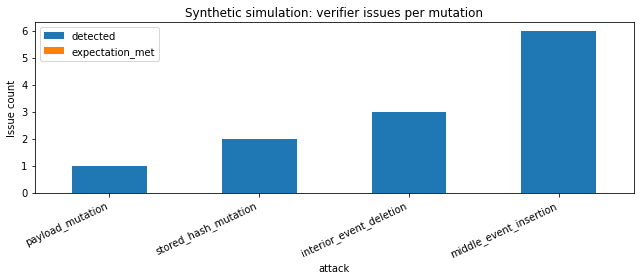

In [8]:
plot_df = attack_df.set_index("attack")[["detected", "expectation_met"]].astype(int)
ax = plot_df.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Boolean outcome (1 = yes)")
ax.set_title("Synthetic simulation: audit tampering detection")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

issue_counts = attack_df.set_index("attack")["issue_count"]
issue_counts.plot(kind="bar", figsize=(9, 4), title="Synthetic simulation: verifier issues per mutation")
plt.ylabel("Issue count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 8. Assertions and CSV exports

In [9]:
assert verify_chain(audit_log)["valid"]
assert not verify_chain(payload_mutation)["valid"]
assert not verify_chain(hash_mutation)["valid"]
assert not verify_chain(deletion)["valid"]
assert not verify_chain(insertion)["valid"]
assert verify_chain(rewritten_log)["valid"]  # deliberately demonstrates the trust-anchor limitation
assert not head_comparison["heads_match"]
assert attack_df["expectation_met"].all()

audit_df.to_csv("trustsr_lab02_07_synthetic_audit_log.csv", index=False)
attack_df.to_csv("trustsr_lab02_07_tamper_detection_results.csv", index=False)
pd.DataFrame([head_comparison]).to_csv("trustsr_lab02_07_trusted_head_limitation.csv", index=False)

print("PASS: intact hash chain verified.")
print("PASS: payload, hash, deletion, and insertion mutations detected.")
print("PASS: whole-log rewrite demonstrates need for independent trusted-head anchoring.")
print("Generated CSVs:")
print("- trustsr_lab02_07_synthetic_audit_log.csv")
print("- trustsr_lab02_07_tamper_detection_results.csv")
print("- trustsr_lab02_07_trusted_head_limitation.csv")
print("All Lab 02.07 assertions passed.")

PASS: intact hash chain verified.
PASS: payload, hash, deletion, and insertion mutations detected.
PASS: whole-log rewrite demonstrates need for independent trusted-head anchoring.
Generated CSVs:
- trustsr_lab02_07_synthetic_audit_log.csv
- trustsr_lab02_07_tamper_detection_results.csv
- trustsr_lab02_07_trusted_head_limitation.csv
All Lab 02.07 assertions passed.


## 9. Interpretation and limitations

### Synthetic findings
The verifier should detect local payload edits, stored-hash changes, interior deletion, and insertion that does not rebuild the chain. The deliberate whole-history rewrite test demonstrates that a freshly recomputed chain can be internally valid even after history changes.

### What this does not prove
- It does not prove tamper resistance if an attacker controls both the log and its trusted head.
- It does not provide authenticated remote anchoring, access control, durable append-only storage, key management, or production monitoring.
- The sample log is synthetic and not generated by a deployed TRUSTSR agent.
- Detection rates from these hand-selected cases are not generalizable security metrics.

### Next step
Lab 02.08 should connect audit records to the SQLite checkpoint transaction and test consistency between the transaction outcome and audit record, including failures between commit and log append. Until then, describe this as an isolated synthetic audit-log prototype, not an integrated TRUSTSR implementation.